## Bonus Question
### Create a random split of 80% of the dataset into training set and 20% into a test set. Train a multinomial na¨ıve Bayes classifier, using a “bag of words” representation. Use again different values of smoothing hyperparameter α, common amongst all features, ranging from 2−15 to 25, and measure only accuracy on the test set this time. Repeat these experiment 10 times, using different random seeds to generate different random splits, and compute average accuracy and standard deviation. Plot the average accuracy a function of α, showing also confidence intervals around the average (± the standard deviation). For the α value that maximizes the average accuracy, report the words corresponding to the 5 highest parameters in each class. 

### You should be able to repurpose code from the last question for most of this question. To code the multinomial na¨ıve Bayes classifier, you are encouraged to use Python’s Scikit Learn class sklearn.naive bayes.MultinomialNB: read its documentation! A program that processes the dataset from the UCI repository so that it can be handled by this class is provided along with this handout. The program directly converts the above dataset into samples where each word is in a “bag of words” representation.

Samples: 1099  Words: 3977  Classes: ['###' 'AIMX' 'AIMX--on' 'BASE' 'CONT' 'CONT--these' 'MISC' 'MISC--for'
 'MISC--in' 'MISC--on' 'MISC--several' 'MISC--specifically,' 'MISC--the'
 'OWNX' 'OWNX--after' 'OWNX--we']
alpha = 2^-15  accuracy = 0.7064 +/- 0.0249
alpha = 2^-14  accuracy = 0.7023 +/- 0.0271
alpha = 2^-13  accuracy = 0.6914 +/- 0.0300
alpha = 2^-12  accuracy = 0.6741 +/- 0.0351
alpha = 2^-11  accuracy = 0.6532 +/- 0.0360
alpha = 2^-10  accuracy = 0.6268 +/- 0.0376
alpha = 2^-9   accuracy = 0.5968 +/- 0.0394
alpha = 2^-8   accuracy = 0.5718 +/- 0.0342
alpha = 2^-7   accuracy = 0.5550 +/- 0.0323
alpha = 2^-6   accuracy = 0.5527 +/- 0.0306
alpha = 2^-5   accuracy = 0.5600 +/- 0.0289
alpha = 2^-4   accuracy = 0.5700 +/- 0.0329
alpha = 2^-3   accuracy = 0.5859 +/- 0.0409
alpha = 2^-2   accuracy = 0.6155 +/- 0.0333
alpha = 2^-1   accuracy = 0.6682 +/- 0.0312
alpha = 2^0    accuracy = 0.7168 +/- 0.0310
alpha = 2^1    accuracy = 0.7300 +/- 0.0309
alpha = 2^2    accuracy = 0.6868 +/-

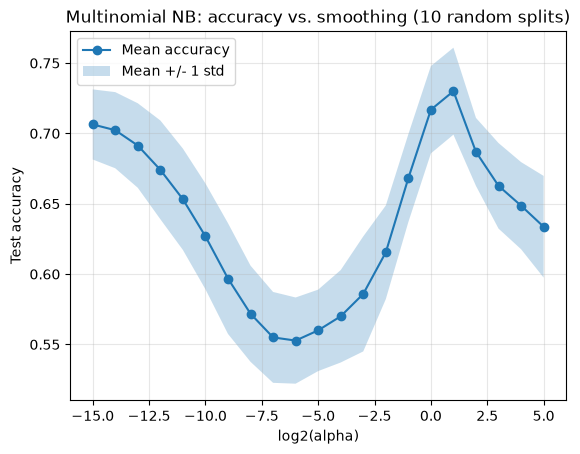


Best alpha: 2^1 = 2 (mean accuracy = 0.7300)

Class '###' - top 5 words:
   abstract        P(word | class) = 0.0034
   introduction    P(word | class) = 0.0031
   without         P(word | class) = 0.0002
   190             P(word | class) = 0.0002
   1937            P(word | class) = 0.0002

Class 'AIMX' - top 5 words:
   we              P(word | class) = 0.0030
   this            P(word | class) = 0.0026
   paper           P(word | class) = 0.0021
   symbol          P(word | class) = 0.0016
   study           P(word | class) = 0.0015

Class 'AIMX--on' - top 5 words:
   paper           P(word | class) = 0.0005
   maker           P(word | class) = 0.0005
   value           P(word | class) = 0.0005
   theory          P(word | class) = 0.0005
   reference       P(word | class) = 0.0005

Class 'BASE' - top 5 words:
   citation        P(word | class) = 0.0024
   we              P(word | class) = 0.0010
   our             P(word | class) = 0.0010
   model           P(word | class) = 0.0008

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score


# 1. Load the data ---------------------------------------------------------
import glob
import os
import re
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

DATA_DIR = "."   # folder that contains "labeled_articles" and "word_lists"


def read_labeled_file(path):
    rows = []
    with open(path, encoding="utf-8", errors="ignore") as f:
        for line in f:
            parts = line.strip().split(None, 1)   # split on first whitespace
            if len(parts) < 2:                    # blank or malformed line: skip
                continue
            rows.append((parts[0].strip(), parts[1].strip()))
    return rows

def load_data():
    # Group the 3 annotator files of each article together.
    # Filename: [DOMAIN]_annotate[1-10]_[ARTICLE_ID]_[ANNOTATOR].txt
    articles = {}
    pattern = re.compile(r"^(.*)_([123])\.txt$")
    for path in glob.glob(os.path.join(DATA_DIR, "labeled_articles", "*.txt")):
        match = pattern.match(os.path.basename(path))
        if match:
            name, annotator = match.group(1), int(match.group(2))
            articles.setdefault(name, {})[annotator] = read_labeled_file(path)

    sentences, labels = [], []
    for name, files in articles.items():
        if len(files) != 3 or len({len(rows) for rows in files.values()}) != 1:
            print("Skipping", name, "(missing annotator or different number of sentences)")
            continue
        # Go through the sentences one by one and take the majority label
        for k in range(len(files[3])):
            votes = [files[a][k][0] for a in (1, 2, 3)]
            label, count = Counter(votes).most_common(1)[0]
            if count == 1:               # no majority: use the expert (annotator 3)
                label = files[3][k][0]
            sentences.append(files[3][k][1])
            labels.append(label)

    # Stopwords file (25 words) from the word_lists folder
    stop_path = glob.glob(os.path.join(DATA_DIR, "word_lists", "*stop*"))[0]
    with open(stop_path) as f:
        stopwords = [w.strip() for w in f if w.strip()]

    # Bag of words: count how many times each word appears in each sentence
    vectorizer = CountVectorizer(stop_words=stopwords)
    X = vectorizer.fit_transform(sentences)
    return X, np.array(labels), vectorizer.get_feature_names_out()



X, y, words = load_data()
y = np.array(y)
words = np.array(words)
print("Samples:", X.shape[0], " Words:", X.shape[1], " Classes:", np.unique(y))

# 2. Experiment: 10 random splits x 21 alpha values --------------------------
alphas = [2.0 ** p for p in range(-15, 6)]   # 2^-15 ... 2^5
n_repeats = 10

# accuracies[r, a] = accuracy for random split r and alpha number a
accuracies = np.zeros((n_repeats, len(alphas)))

for r in range(n_repeats):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=r      # a different seed each repeat
    )
    for a, alpha in enumerate(alphas):
        model = MultinomialNB(alpha=alpha)
        model.fit(X_train, y_train)
        accuracies[r, a] = accuracy_score(y_test, model.predict(X_test))

mean_acc = accuracies.mean(axis=0)   # average over the 10 repeats
std_acc = accuracies.std(axis=0)     # standard deviation over the 10 repeats

for alpha, m, s in zip(alphas, mean_acc, std_acc):
    print("alpha = 2^%-3d  accuracy = %.4f +/- %.4f" % (np.log2(alpha), m, s))

# 3. Plot average accuracy with +/- one standard deviation -------------------
x = np.log2(alphas)
plt.plot(x, mean_acc, "o-", label="Mean accuracy")
plt.fill_between(x, mean_acc - std_acc, mean_acc + std_acc, alpha=0.25,
                 label="Mean +/- 1 std")
plt.xlabel("log2(alpha)")
plt.ylabel("Test accuracy")
plt.title("Multinomial NB: accuracy vs. smoothing (10 random splits)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("multinomial_nb_accuracy.png", dpi=150)
plt.show()

# 4. Top 5 words per class at the best alpha ---------------------------------
best = int(np.argmax(mean_acc))
best_alpha = alphas[best]
print("\nBest alpha: 2^%d = %g (mean accuracy = %.4f)"
      % (np.log2(best_alpha), best_alpha, mean_acc[best]))

# Train once at the best alpha, using the first split (seed 0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0
)
model = MultinomialNB(alpha=best_alpha)
model.fit(X_train, y_train)

# feature_log_prob_ has one row per class and one column per word:
# it holds log P(word | class). Bigger value = word more likely in that class.
for i, label in enumerate(model.classes_):
    top5 = np.argsort(model.feature_log_prob_[i])[::-1][:5]   # indices of 5 largest
    print("\nClass '%s' - top 5 words:" % label)
    for j in top5:
        print("   %-15s P(word | class) = %.4f"
              % (words[j], np.exp(model.feature_log_prob_[i][j])))